# A practical introduction to machine learning for time series

This is a hands-on, end-to-end lesson in **forecasting**: predicting future values using information available when a prediction is made. We will generate two fictional datasets, explore them, build and evaluate scikit-learn models, and fit a seasonal ARIMA model with pmdarima.

## What you will learn
1. Recognize trends, seasonality, autocorrelation, and data leakage.
2. Convert a series into supervised examples using calendar, lag, and rolling features.
3. Use chronological splits, walk-forward cross-validation, pipelines, baselines, and regression metrics.
4. Fit and interpret an automatically selected seasonal ARIMA model and its prediction intervals.
5. Distinguish **one-step-ahead forecasts**, updated as actual observations arrive, from a **fixed-origin, multi-step forecast**.

Run the cells in order. The examples are deliberately synthetic: the numbers are not real measurements, and good performance here does not guarantee performance on real data. Expect roughly a few minutes, depending on your computer. An exercise section with hints and sample solutions is at the end.

## 0. Setup and the forecasting contract

Select your project's `ml` kernel in VS Code. This lesson needs Python, Jupyter, NumPy, pandas, matplotlib, scikit-learn, pmdarima, and statsmodels. If packages are missing, install them in the **selected kernel** (uncomment the line below), then restart the kernel and run all cells again. If pmdarima reports a NumPy binary compatibility error, install compatible current versions of both in a fresh environment rather than ignoring the error.

Before modelling, write down the *forecasting contract*: What is predicted? When is the forecast made? Which inputs are actually known at that moment? How far ahead is it needed? What error is costly? Our first task predicts today's energy demand immediately before it is observed, using calendar information and measurements **through yesterday**. We assume yesterday's actual demand and temperature are available before today's forecast.

In [ ]:
# Uncomment only if needed, then restart the kernel:
# %pip install numpy pandas matplotlib scikit-learn pmdarima statsmodels

In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
import pmdarima as pm

from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

print(f"Python: {sys.version.split()[0]}")
print(f"NumPy: {np.__version__}; pandas: {pd.__version__}; "
      f"scikit-learn: {sklearn.__version__}; pmdarima: {pm.__version__}")

Python: 3.12.15
NumPy: 2.5.3; pandas: 3.0.6; scikit-learn: 1.9.1; pmdarima: 0.0.0


## 1. Create two reproducible dummy datasets

* **Daily energy demand:** three years of daily demand and temperature, with weekly patterns, annual variation, a gentle trend, and noise. We will use it for scikit-learn.
* **Monthly sales:** eight years of fictional monthly sales with trend, annual seasonality, and noise. We will use it for ARIMA.

Both use fixed random seeds. Each row represents one observation at a regular frequency. In real work, check units, timestamps, time zones, missing dates, duplicates, outliers, and whether values were revised after the forecast time. The data-generating process is intentionally simplified.

In [2]:
def make_daily_energy(seed=42):
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2021-01-01", periods=3 * 365, freq="D")
    t = np.arange(len(dates))
    temperature = 15 + 10 * np.sin(2 * np.pi * (t - 100) / 365.25) + rng.normal(0, 2, len(t))
    weekend = (dates.dayofweek >= 5).astype(int)
    demand = (
        100 + 0.015 * t - 12 * weekend
        + 0.12 * (temperature - 18) ** 2
        + 3 * np.sin(2 * np.pi * t / 7)
        + rng.normal(0, 3, len(t))
    )
    return pd.DataFrame({"date": dates, "temperature_c": temperature, "demand": demand})


def make_monthly_sales(seed=123):
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2016-01-01", periods=8 * 12, freq="MS")
    t = np.arange(len(dates))
    sales = 200 + 1.0 * t + 25 * np.sin(2 * np.pi * t / 12) + rng.normal(0, 5, len(t))
    return pd.DataFrame({"date": dates, "sales": sales})


daily = make_daily_energy()
monthly = make_monthly_sales()
print("Daily data:", daily.shape, "| Monthly data:", monthly.shape)
display(daily.head(), monthly.head())

Daily data: (1095, 3) | Monthly data: (96, 2)


,date,temperature_c,demand
0,2021-01-01,5.720897,121.772043
1,2021-01-02,3.007346,122.071611
2,2021-01-03,6.567002,108.124067
3,2021-01-04,6.928953,118.975810
4,2021-01-05,1.130423,136.634144


,date,sales
0,2016-01-01,195.054393
1,2016-02-01,211.661067
2,2016-03-01,230.090261
3,2016-04-01,228.969872
4,2016-05-01,230.251790


These datasets live in memory and are regenerated on every run. To save CSV files for use elsewhere, run the optional cell; files will be written relative to the notebook's current working directory. Reload with `pd.read_csv("synthetic_daily_energy.csv", parse_dates=["date"])`.

In [ ]:
# Optional: uncomment to export the generated datasets.
# daily.to_csv("synthetic_daily_energy.csv", index=False)
# monthly.to_csv("synthetic_monthly_sales.csv", index=False)

daily missing values: {'date': 0, 'temperature_c': 0, 'demand': 0}
monthly missing values: {'date': 0, 'sales': 0}


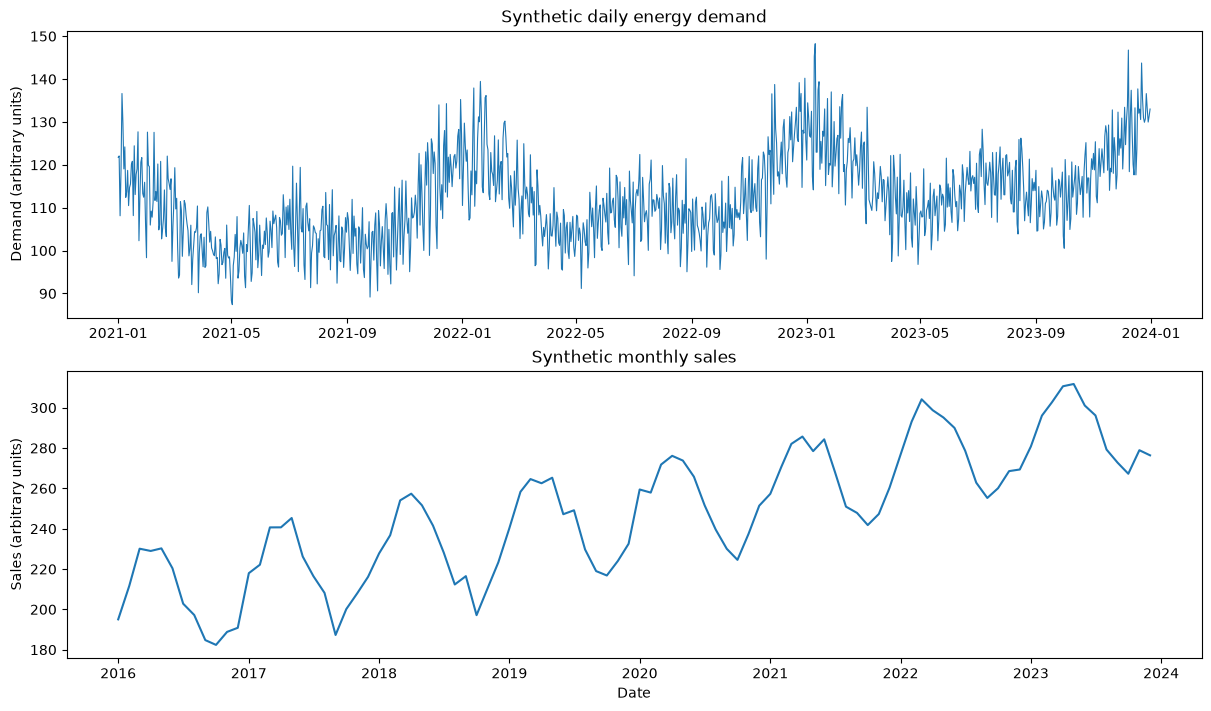

In [3]:
for name, frame, freq in [
    ("daily", daily, "D"),
    ("monthly", monthly, "MS"),
]:
    assert frame["date"].is_monotonic_increasing and frame["date"].is_unique
    expected = pd.date_range(frame["date"].iloc[0], periods=len(frame), freq=freq)
    assert pd.DatetimeIndex(frame["date"]).equals(expected)
    print(name, "missing values:", frame.isna().sum().to_dict())

fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(daily["date"], daily["demand"], linewidth=0.8)
axes[0].set(title="Synthetic daily energy demand", ylabel="Demand (arbitrary units)")
axes[1].plot(monthly["date"], monthly["sales"])
axes[1].set(title="Synthetic monthly sales", ylabel="Sales (arbitrary units)", xlabel="Date")
plt.show()

### Reading a time series

A **trend** is a long-run change in level. **Seasonality** is a recurring pattern at a known period (for example 7 daily observations per week or 12 monthly observations per year). **Autocorrelation** means past and present values are related. Noise and unusual events can hide all three. Decomposition and autocorrelation plots are useful diagnostics, but always check whether the pattern is stable and makes sense for the problem.

The following summaries are exploratory, not proof of causation. In a real project, avoid using insights from the final test period to redesign the model; reserve that period before exploratory model development.

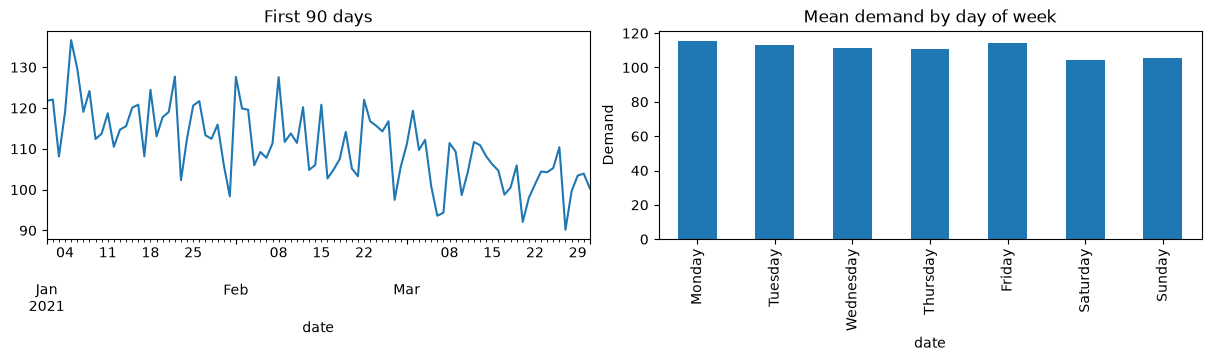

In [4]:
explore = daily.iloc[:800].copy()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
explore.set_index("date")["demand"].iloc[:90].plot(ax=axes[0], title="First 90 days")
explore.groupby(explore["date"].dt.day_name())["demand"].mean().reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
).plot.bar(ax=axes[1], title="Mean demand by day of week")
axes[1].set_ylabel("Demand")
plt.show()

## 2. Make a supervised learning table without looking ahead

For date *t*, the target is demand on *t*. Features include:

* `lag_1`, `lag_7`, `lag_14`: actual demand 1, 7, and 14 days ago.
* `rolling_mean_7`: the mean of days *t-7* through *t-1*, **not including** today's target.
* `temperature_lag_1`: yesterday's measured temperature, not today's unknown measurement.
* Calendar features known at forecast time. Sine/cosine encode annual seasonality as a cycle.

The first 14 rows cannot have all lag features, so we drop them. For one-step evaluation, later test rows can use earlier **actual** test observations, because the forecasting contract says actuals arrive each day. This is not a forecast of the entire test window made all at once.

In [5]:
def make_features(frame):
    frame = frame.sort_values("date").copy()
    if frame["date"].duplicated().any():
        raise ValueError("Dates must be unique before constructing lag features.")
    if not pd.DatetimeIndex(frame["date"]).equals(
        pd.date_range(frame["date"].iloc[0], periods=len(frame), freq="D")
    ):
        raise ValueError("Daily rows must be consecutive; resolve missing dates first.")
    dates = frame["date"]
    frame["day_of_week"] = dates.dt.dayofweek
    frame["is_weekend"] = (dates.dt.dayofweek >= 5).astype(int)
    frame["year_sin"] = np.sin(2 * np.pi * dates.dt.dayofyear / 365.25)
    frame["year_cos"] = np.cos(2 * np.pi * dates.dt.dayofyear / 365.25)
    for lag in (1, 7, 14):
        frame[f"lag_{lag}"] = frame["demand"].shift(lag)
    frame["rolling_mean_7"] = frame["demand"].shift(1).rolling(7).mean()
    frame["temperature_lag_1"] = frame["temperature_c"].shift(1)
    return frame.dropna().reset_index(drop=True)


features = [
    "day_of_week", "is_weekend", "year_sin", "year_cos",
    "lag_1", "lag_7", "lag_14", "rolling_mean_7", "temperature_lag_1",
]
examples = make_features(daily)
display(examples[["date", "demand"] + features].head())
print(f"Usable examples: {len(examples)} of {len(daily)}")

,date,demand,day_of_week,is_weekend,year_sin,year_cos,lag_1,lag_7,lag_14,rolling_mean_7,temperature_lag_1
0,2021-01-15,120.077690,4,0,0.255182,0.966893,115.545297,124.187617,121.772043,115.678993,7.281987
1,2021-01-16,120.821448,5,1,0.271777,0.962360,120.077690,112.407263,122.071611,115.091861,5.976748
2,2021-01-17,108.162233,6,1,0.288291,0.957543,120.821448,113.719543,108.124067,116.293887,3.340316
3,2021-01-18,124.440505,0,0,0.304719,0.952442,108.162233,118.710705,118.975810,115.499986,5.816516
4,2021-01-19,113.072377,1,0,0.321058,0.947060,124.440505,110.491144,136.634144,116.318529,3.184299


Usable examples: 1081 of 1095


In [6]:
# A concrete leakage check: changing today's target or any future data must
# not change today's features.
check_index = 100
changed = daily.copy()
changed.loc[check_index:, ["demand", "temperature_c"]] += 10_000
date_to_check = daily.loc[check_index, "date"]
original_row = examples.set_index("date").loc[date_to_check, features]
changed_row = make_features(changed).set_index("date").loc[date_to_check, features]
assert np.allclose(original_row.astype(float), changed_row.astype(float))
print("Leakage check passed for an example date:", date_to_check.date())

Leakage check passed for an example date: 2021-04-11


## 3. Chronological train/test split and baselines

Never randomly shuffle a forecasting dataset: it would let training see observations later than those being predicted. Keep the **last 20%** of usable dates as a final test set. Only the earlier training period is used to select the model. The test set is touched once for final comparison.

Two useful benchmarks are **persistence** (predict yesterday's value) and **seasonal naive** (predict the value from 7 days ago). A complex model should justify its cost by beating an appropriate baseline.

MAE is the average absolute error in target units. RMSE also has target units but penalizes larger mistakes more strongly. Lower is better for both. MAPE can be unstable when actual values are near zero; do not use it blindly.

In [7]:
split_at = int(len(examples) * 0.8)
train = examples.iloc[:split_at].copy()
test = examples.iloc[split_at:].copy()
X_train, y_train = train[features], train["demand"]
X_test, y_test = test[features], test["demand"]
assert train["date"].max() < test["date"].min()
print("Train:", train["date"].min().date(), "to", train["date"].max().date(), len(train))
print("Test: ", test["date"].min().date(), "to", test["date"].max().date(), len(test))


def regression_scores(actual, predicted):
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
    }


baseline_scores = {
    "Persistence (lag 1)": regression_scores(y_test, test["lag_1"]),
    "Seasonal naive (lag 7)": regression_scores(y_test, test["lag_7"]),
}
display(pd.DataFrame(baseline_scores).T.round(2))

Train: 2021-01-15 to 2023-05-28 864
Test:  2023-05-29 to 2023-12-31 217


,MAE,RMSE
Persistence (lag 1),6.16,7.78
Seasonal naive (lag 7),4.70,6.09


## 4. Time-aware cross-validation and scikit-learn pipelines

`TimeSeriesSplit` uses expanding training windows: fit on the past, validate on the next block, then repeat. Each fold's features assume the same daily arrival of actual observations as the final test. Do not fit scalers, imputers, feature selection, or other learned transformations on all rows before splitting; place them in a pipeline so each fold learns only from its training slice.

We compare a scaled linear Ridge model with a nonlinear random forest. The small hyperparameter search below uses only training folds and selects by average validation MAE. It is intentionally modest, not a claim that these are optimal models. A `gap` or embargo may be needed when labels span multiple future periods or data arrive late.

In [8]:
cv = TimeSeriesSplit(n_splits=4)
for fold, (fit_idx, val_idx) in enumerate(cv.split(X_train), start=1):
    print(
        f"Fold {fold}: fit {train['date'].iloc[fit_idx[0]].date()} to "
        f"{train['date'].iloc[fit_idx[-1]].date()}, validate "
        f"{train['date'].iloc[val_idx[0]].date()} to {train['date'].iloc[val_idx[-1]].date()}"
    )

candidates = {
    "Ridge (alpha=1)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Ridge (alpha=100)": make_pipeline(StandardScaler(), Ridge(alpha=100.0)),
    "Random forest (leaf=3)": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=3, random_state=42, n_jobs=-1
    ),
    "Random forest (leaf=10)": RandomForestRegressor(
        n_estimators=100, min_samples_leaf=10, random_state=42, n_jobs=-1
    ),
}

fold_results = []
for name, model in candidates.items():
    for fold, (fit_idx, val_idx) in enumerate(cv.split(X_train), start=1):
        fitted = clone(model).fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        prediction = fitted.predict(X_train.iloc[val_idx])
        fold_results.append({
            "model": name, "fold": fold,
            "MAE": mean_absolute_error(y_train.iloc[val_idx], prediction),
        })

cv_results = pd.DataFrame(fold_results)
cv_summary = cv_results.groupby("model")["MAE"].agg(["mean", "std"]).sort_values("mean")
display(cv_summary.round(2))
best_name = cv_summary.index[0]
print("Selected using training folds only:", best_name)

Fold 1: fit 2021-01-15 to 2021-07-09, validate 2021-07-10 to 2021-12-28
Fold 2: fit 2021-01-15 to 2021-12-28, validate 2021-12-29 to 2022-06-18
Fold 3: fit 2021-01-15 to 2022-06-18, validate 2022-06-19 to 2022-12-07
Fold 4: fit 2021-01-15 to 2022-12-07, validate 2022-12-08 to 2023-05-28


,mean,std
model,,
Random forest (leaf=10),4.55,0.41
Random forest (leaf=3),4.61,0.47
Ridge (alpha=100),4.74,0.98
Ridge (alpha=1),7.20,5.98


Selected using training folds only: Random forest (leaf=10)


,MAE,RMSE
Selected: Random forest (leaf=10),4.00,4.99
Seasonal naive (lag 7),4.70,6.09
Persistence (lag 1),6.16,7.78


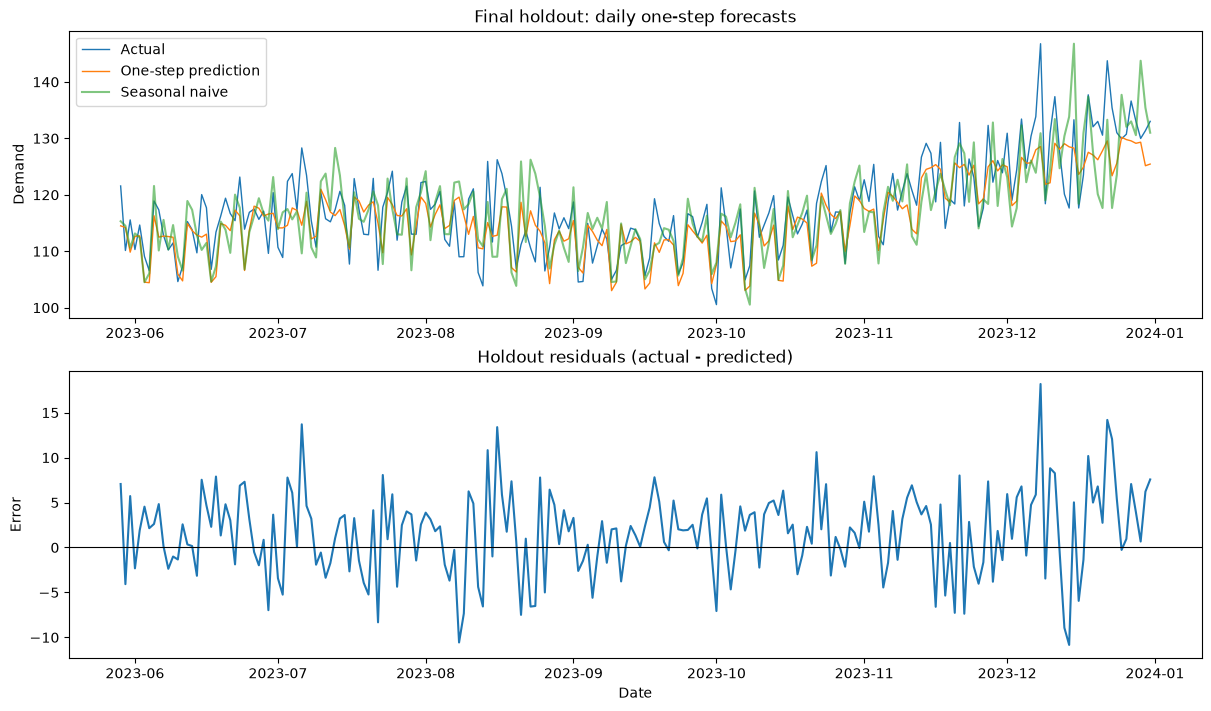

Mean signed error (positive means underprediction): 1.68


In [9]:
best_model = clone(candidates[best_name]).fit(X_train, y_train)
test_prediction = best_model.predict(X_test)
all_scores = {
    **baseline_scores,
    f"Selected: {best_name}": regression_scores(y_test, test_prediction),
}
display(pd.DataFrame(all_scores).T.round(2).sort_values("MAE"))

fig, axes = plt.subplots(2, 1, figsize=(12, 7), constrained_layout=True)
axes[0].plot(test["date"], y_test, label="Actual", linewidth=1)
axes[0].plot(test["date"], test_prediction, label="One-step prediction", linewidth=1)
axes[0].plot(test["date"], test["lag_7"], label="Seasonal naive", alpha=0.6)
axes[0].set(title="Final holdout: daily one-step forecasts", ylabel="Demand")
axes[0].legend()
residuals = y_test.to_numpy() - test_prediction
axes[1].plot(test["date"], residuals)
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="Holdout residuals (actual - predicted)", ylabel="Error", xlabel="Date")
plt.show()
print("Mean signed error (positive means underprediction):", round(residuals.mean(), 2))

### Interpreting the result

Check whether the chosen model improves on both baselines and whether errors cluster by date or weekday. Cross-validation scores are for model selection; the final holdout is an estimate on a later period. If you repeatedly redesign the model after seeing the test score, it becomes another validation set; reserve a new untouched test period.

This evaluation refits the chosen model once on the training data and then supplies observed lagged inputs each day; it does **not** refit the model each day. For a fixed-origin 30-day forecast, future actual lags are not available. You must recursively feed predictions back into lag features or train direct horizon-specific models, and evaluate using that same procedure. In either case, future exogenous inputs must be genuinely known or separately forecast.

## 5. Seasonal ARIMA with pmdarima

ARIMA is a statistical forecasting family. Its nonseasonal order `(p, d, q)` specifies autoregressive terms, differencing, and moving-average terms. Seasonal `(P, D, Q, m)` adds the same ideas at a seasonal period `m`; for monthly data with annual seasonality, `m=12`. Differencing can help with changing level, but too much differencing can be harmful.

`auto_arima` searches candidate orders using an information criterion (AIC here), not test-set accuracy. It does not guarantee the best model, establish causality, or replace validation. We limit the search to keep the lesson practical and fix both differencing orders (`d=1`, `D=1`) rather than estimating them automatically. Watch for convergence warnings: selected models can be unreliable when optimization fails. We fit on the first 84 months and forecast the next 12 **all at once**; no actual test values enter this forecast. The seasonal naive baseline repeats the last observed year.

In [10]:
sales_series = monthly.set_index("date")["sales"].asfreq("MS")
horizon = 12
sales_train = sales_series.iloc[:-horizon]
sales_test = sales_series.iloc[-horizon:]
assert sales_train.index.max() < sales_test.index.min()
print("Training months:", len(sales_train), "| fixed forecast horizon:", len(sales_test))

sarima = pm.auto_arima(
    sales_train,
    seasonal=True, m=12,
    start_p=0, start_q=0, max_p=1, max_q=1,
    start_P=0, start_Q=0, max_P=1, max_Q=1,
    d=1, D=1,
    information_criterion="aic",
    stepwise=True, maxiter=30, suppress_warnings=False,
    error_action="warn",
)
print("Selected order:", sarima.order, "seasonal order:", sarima.seasonal_order)
print("Selected model optimizer:", sarima.arima_res_.mle_retvals)
print(sarima.summary())

Training months: 84 | fixed forecast horizon: 12


/home/carsonc/miniconda3/envs/ml/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/home/carsonc/miniconda3/envs/ml/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
/home/carsonc/miniconda3/envs/ml/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Selected order: (0, 1, 1) seasonal order: (1, 1, 1, 12)
Selected model optimizer: {'fopt': np.float64(2.6403986073026964), 'gopt': array([ 8.78408457e-08, -4.03570510e-06,  1.37609923e-06, -7.09254877e-07]), 'fcalls': 130, 'warnflag': 0, 'converged': True, 'iterations': 23}
                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                   84
Model:             SARIMAX(0, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -221.793
Date:                            Thu, 12 Nov 2026   AIC                            451.587
Time:                                    17:40:22   BIC                            460.638
Sample:                                01-01-2016   HQIC                           455.186
                                     - 12-01-2022                                         
Covariance Type:                              opg                                       

/home/carsonc/miniconda3/envs/ml/lib/python3.12/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Warnings during the search can refer to candidate models, not necessarily the selected model. Check `converged` in the selected model's optimizer output above. If it is false, investigate the data and model, try a simpler specification or a higher iteration limit, and do not treat its forecast as reliable without further validation.

,MAE,RMSE
Seasonal naive,10.34,11.76
Auto SARIMA,4.01,4.66


Observed 95% interval coverage on 12 months: 100.0%


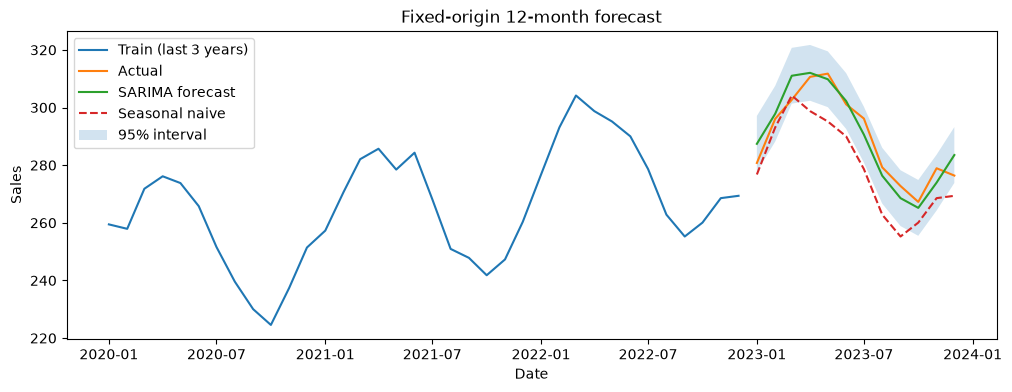

In [11]:
forecast, confidence = sarima.predict(n_periods=horizon, return_conf_int=True, alpha=0.05)
forecast = np.asarray(forecast)
confidence = np.asarray(confidence)
seasonal_naive = np.resize(sales_train.iloc[-12:].to_numpy(), horizon)
sales_scores = {
    "Seasonal naive": regression_scores(sales_test, seasonal_naive),
    "Auto SARIMA": regression_scores(sales_test, forecast),
}
display(pd.DataFrame(sales_scores).T.round(2))
coverage = np.mean(
    (sales_test.to_numpy() >= confidence[:, 0]) & (sales_test.to_numpy() <= confidence[:, 1])
)
print(f"Observed 95% interval coverage on {horizon} months: {coverage:.1%}")

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(sales_train.index[-36:], sales_train.iloc[-36:], label="Train (last 3 years)")
ax.plot(sales_test.index, sales_test, label="Actual")
ax.plot(sales_test.index, forecast, label="SARIMA forecast")
ax.plot(sales_test.index, seasonal_naive, label="Seasonal naive", linestyle="--")
ax.fill_between(sales_test.index, confidence[:, 0], confidence[:, 1], alpha=0.2, label="95% interval")
ax.set(title="Fixed-origin 12-month forecast", ylabel="Sales", xlabel="Date")
ax.legend()
plt.show()

The 95% interval is a model-based prediction interval, not a guarantee: its reliability depends on model assumptions and how well the past represents the future. Twelve holdout observations are far too few to establish calibration. Check interval coverage over many rolling forecast origins, and report it alongside point accuracy.

SARIMA here is **univariate**: it only uses past sales. pmdarima can accept exogenous regressors (`X`), but their future values must be known or forecast for every horizon. Do not pass realized future covariates to a backtest unless those values truly would have been known when the forecast was made.

## 6. Diagnostics, backtesting, and next steps

A good model can still fail after deployment. Inspect residuals for bias, changing variance, leftover seasonality, and correlated errors. For a genuine fixed-horizon evaluation, refit at multiple historical origins, forecast the full horizon at each origin, and compare predictions to observations at each lead time. Be careful that a window used to choose orders is not also reported as a final unbiased test.

The diagnostic below examines **training** residuals. Early residuals can be affected by initialization and differencing; the picture is a warning tool, not a formal proof of adequacy. Also inspect forecast errors on held-out periods and compare across forecast horizons.

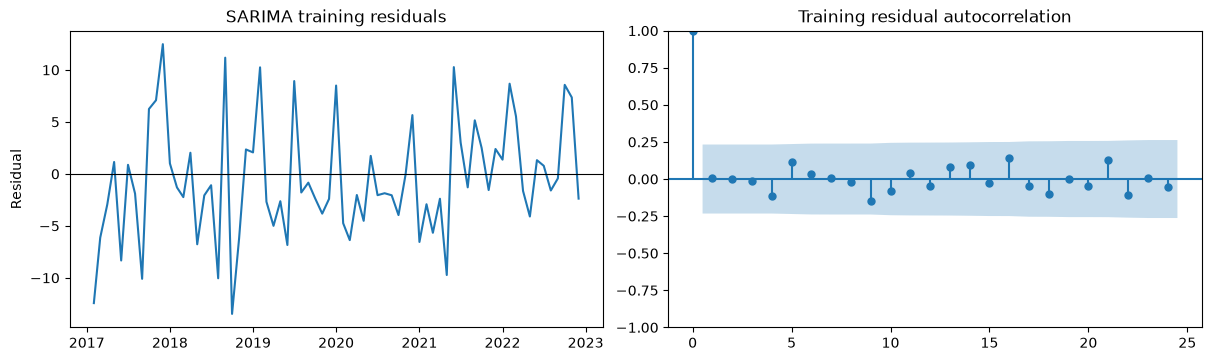

In [12]:
from statsmodels.graphics.tsaplots import plot_acf

training_residuals = pd.Series(np.asarray(sarima.resid()), index=sales_train.index).iloc[13:]
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
axes[0].plot(training_residuals.index, training_residuals)
axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set(title="SARIMA training residuals", ylabel="Residual")
plot_acf(training_residuals, lags=24, ax=axes[1])
axes[1].set_title("Training residual autocorrelation")
plt.show()

### Real-world checklist

- **Define the decision:** target, horizon, cadence, units, cost of errors, and prediction-time data availability.
- **Audit the data:** regularize timestamps carefully; handle missingness and outliers using only information available at prediction time. Consider revisions and publication delays.
- **Split by time:** reserve a recent test period; perform rolling-origin validation on earlier data. Consider gaps, multiple entities, and distribution shifts.
- **Beat baselines:** use persistence and an appropriate seasonal naive forecast; compare at each relevant horizon and segment.
- **Avoid leakage:** shift rolling features, fit transformations inside folds, and use only known or forecast future covariates.
- **Communicate uncertainty:** check intervals and error distributions; do not promise a 95% interval is calibrated without evidence.
- **Deploy and monitor:** save the pipeline, reproduce feature generation, track drift and delayed ground truth, retrain deliberately, and compare against a fallback baseline.

Further reading: [scikit-learn time-series cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split), [scikit-learn common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html), [pmdarima documentation](https://alkaline-ml.com/pmdarima/), and [Forecasting: Principles and Practice](https://otexts.com/fpp3/).

## 7. Practice exercises

1. **Features:** add a 28-day lag and a shifted 28-day mean. Check that changing today's demand does not change today's features. Re-run the time split and selection process.
2. **Metrics:** calculate MAE separately for weekdays and weekends in the held-out daily data. What might cause a difference?
3. **Fixed-origin forecasts:** create a 24-month seasonal-naive forecast by repeating the final 12 training observations twice. Why must it not use actual sales from the first test year?
4. **Backtest:** choose at least three historical origins within the monthly training period; at each, fit only to earlier observations and forecast 12 months. Compare average MAE per horizon against seasonal naive. Leave the final 12-month test untouched while developing.
5. **Experiment:** change the random seed or increase noise, then repeat the analysis. How stable are the model rankings?

Try the exercises before looking at these sample solutions for 2 and 3:

In [15]:
# Exercise 1 solution: use DAILY energy demand, not the monthly sales series.
# Run the earlier setup, feature-engineering, and model-selection cells first.

def make_exercise1_features(frame):
    # The existing helper checks daily continuity and creates the original features.
    result = make_features(frame)
    demand = frame.sort_values("date").set_index("date")["demand"]
    new_features = pd.DataFrame({
        # For day t, use demand from t-28, and the mean of t-28 through t-1.
        "lag_28": demand.shift(28),
        "rolling_mean_28": demand.shift(1).rolling(28).mean(),
    })
    result = result.join(new_features, on="date")
    # The first 28 dates cannot have a full history for these two features.
    return result.dropna(subset=["lag_28", "rolling_mean_28"]).reset_index(drop=True)


exercise1 = make_exercise1_features(daily)
exercise1_features = features + ["lag_28", "rolling_mean_28"]

# Test leakage by changing today's and future demand in the raw data, then
# recomputing features. Pick a date with at least 28 earlier observations.
check_date = daily.sort_values("date")["date"].iloc[100]
changed_daily = daily.copy()
changed_daily.loc[changed_daily["date"] >= check_date, "demand"] += 10_000
changed_exercise1 = make_exercise1_features(changed_daily)
exercise1_original_row = exercise1.set_index("date").loc[check_date, exercise1_features]
exercise1_changed_row = changed_exercise1.set_index("date").loc[check_date, exercise1_features]
pd.testing.assert_series_equal(exercise1_original_row, exercise1_changed_row)
print("Leakage check passed for", check_date.date())

# Keep the original holdout dates, allowing a fair comparison with section 4.
# The extra history removes earlier training rows, not test rows.
original_examples = make_features(daily)
original_split = int(len(original_examples) * 0.8)
test_start = original_examples["date"].iloc[original_split]
exercise1_train = exercise1.loc[exercise1["date"] < test_start].copy()
exercise1_test = exercise1.loc[exercise1["date"] >= test_start].copy()
assert exercise1_train["date"].max() < exercise1_test["date"].min()
print("Training rows:", len(exercise1_train), "| test rows:", len(exercise1_test))

X_ex1 = exercise1_train[exercise1_features]
y_ex1 = exercise1_train["demand"]
exercise1_fold_scores = []
# As in section 4, every validation prediction assumes previous actual daily
# demand is available. Model selection uses only the training period.
for name, model in candidates.items():
    for fold, (fit_idx, val_idx) in enumerate(cv.split(X_ex1), start=1):
        fitted = clone(model).fit(X_ex1.iloc[fit_idx], y_ex1.iloc[fit_idx])
        prediction = fitted.predict(X_ex1.iloc[val_idx])
        exercise1_fold_scores.append({
            "model": name,
            "fold": fold,
            "MAE": mean_absolute_error(y_ex1.iloc[val_idx], prediction),
        })

exercise1_cv = (pd.DataFrame(exercise1_fold_scores)
                .groupby("model")["MAE"].agg(["mean", "std"])
                .sort_values("mean"))
display(exercise1_cv.round(2))
exercise1_best_name = exercise1_cv.index[0]
exercise1_model = clone(candidates[exercise1_best_name]).fit(X_ex1, y_ex1)
exercise1_prediction = exercise1_model.predict(exercise1_test[exercise1_features])

# Compare the selected model and the same naive baselines on the held-out dates.
exercise1_scores = {
    "Persistence (lag 1)": regression_scores(exercise1_test["demand"], exercise1_test["lag_1"]),
    "Seasonal naive (lag 7)": regression_scores(exercise1_test["demand"], exercise1_test["lag_7"]),
    f"Selected: {exercise1_best_name}": regression_scores(exercise1_test["demand"], exercise1_prediction),
}
print("Selected using training folds only:", exercise1_best_name)
display(pd.DataFrame(exercise1_scores).T.round(2).sort_values("MAE"))
# A lower MAE than in section 4 suggests these features helped on this holdout;
# one experiment alone does not establish that they generalize.

Leakage check passed for 2021-04-11
Training rows: 850 | test rows: 217


,mean,std
model,,
Ridge (alpha=100),4.46,0.57
Random forest (leaf=10),4.69,0.57
Random forest (leaf=3),4.71,0.49
Ridge (alpha=1),6.71,5.05


Selected using training folds only: Ridge (alpha=100)


,MAE,RMSE
Selected: Ridge (alpha=100),3.89,4.97
Seasonal naive (lag 7),4.70,6.09
Persistence (lag 1),6.16,7.78


In [ ]:
# calculate MAE separately for weekdays and weekends in the held-out daily data. What might cause a difference?

# segment the same held-out one-step predictions.
segment_errors = pd.DataFrame({
    "segment": np.where(test["is_weekend"].to_numpy() == 1, "weekend", "weekday"),
    "absolute_error": np.abs(y_test.to_numpy() - test_prediction),
})
display(segment_errors.groupby("segment")["absolute_error"].agg(["mean", "count"]).round(2))


# weekend MAE
mae_weekend = segment_errors.loc[segment_errors["segment"] == "weekend", "absolute_error"].mean()
print("MAE for weekends:", mae_weekend)
# weekday MAE
mae_weekday = segment_errors.loc[segment_errors["segment"] == "weekday", "absolute_error"].mean()
print("MAE for weekdays:", mae_weekday)

# more data could help reduce the MAE for weekends, as there are typically fewer weekend observations compared to weekdays.

,mean,count
segment,,
weekday,3.96,155
weekend,4.10,62


MAE for weekends: 4.102580537207588
MAE for weekdays: 3.9560635544354015


In [21]:
# Exercise 3: a fixed-origin forecast, even when the horizon exceeds one season.
naive_24_months = np.tile(sales_train.iloc[-12:].to_numpy(), 2)
assert len(naive_24_months) == 24
print("24-month seasonal-naive forecast:", np.round(naive_24_months, 1))

24-month seasonal-naive forecast: [276.8 293.1 304.2 298.8 295.2 290.  278.6 262.8 255.2 260.1 268.6 269.4
 276.8 293.1 304.2 298.8 295.2 290.  278.6 262.8 255.2 260.1 268.6 269.4]


In [ ]:
# choose at least three historical origins within the monthly training period; 
#   at each, fit only to earlier observations and forecast 12 months. 
# Compare average MAE per horizon against seasonal naive. Leave the final 12-month test untouched while developing.

In [ ]:
# Exercise 2: segment the same held-out one-step predictions.
segment_errors = pd.DataFrame({
    "segment": np.where(test["is_weekend"].to_numpy() == 1, "weekend", "weekday"),
    "absolute_error": np.abs(y_test.to_numpy() - test_prediction),
})
display(segment_errors.groupby("segment")["absolute_error"].agg(["mean", "count"]).round(2))

# Exercise 3: a fixed-origin forecast, even when the horizon exceeds one season.
naive_24_months = np.tile(sales_train.iloc[-12:].to_numpy(), 2)
assert len(naive_24_months) == 24
print("24-month seasonal-naive forecast:", np.round(naive_24_months, 1))